# 🌍 Copernicus Atmosphere Monitoring Service (CAMS) Wrapper Demonstration
### High-Resolution Atmospheric Composition, Aerosols, Particulate Matter, Trace Gases & Solar UV Radiation for East Africa
**Focus Case Study:** Dedan Kimathi University of Technology (DeKUT), Nyeri, Kenya (`-0.398° N, 36.958° E`, Elevation ~1,780m)

---

## 📌 Executive Summary
The **Copernicus Atmosphere Monitoring Service (CAMS)** is Europe's flagship Earth observation program operated by the **European Centre for Medium-Range Weather Forecasts (ECMWF)**. CAMS combines satellite observations, in-situ surface monitoring networks, and advanced atmospheric chemistry models to track:
1. **Aerosols & Desert Dust:** Total Aerosol Optical Depth (AOD at 550nm) and mineral dust mass concentrations from the Sahara, Chalbi, and Somali deserts.
2. **Particulate Matter (PM2.5 & PM10):** Fine and coarse particulate matter concentrations critical for public health epidemiology and WHO air quality compliance.
3. **Trace Gases:** Nitrogen Dioxide ($NO_2$), Surface Ozone ($O_3$), Carbon Monoxide ($CO$), Sulphur Dioxide ($SO_2$), and Ammonia ($NH_3$).
4. **Solar Ultraviolet (UV) Radiation:** Ground-level All-Sky and Clear-Sky UV Index for solar energy degradation and biometeorological health risks.
5. **Operational Forecasting:** Rolling 5-day predictive forecasts for regional environmental management.

### Zero-Key Architecture
Through `masharikiweather.wrappers.cams`, users can query global CAMS operational atmospheric data with **zero API keys, zero registration, and few lines of code**, backed by local **Apache Parquet caching** for sub-millisecond retrieval.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set clean scientific plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

# Import MasharikiWeather CAMS wrapper components
from masharikiweather import (
    CAMS,
    query_cams,
    query_cams_aerosols,
    query_cams_air_quality,
    query_cams_forecast,
    search_cams_parameters,
    list_cams_parameters,
    classify_aqi,
    get_cams_metadata,
)

# Reference Site Coordinates: Dedan Kimathi University of Technology (DeKUT), Nyeri, Kenya
DEKUT_NYERI_LAT = -0.398
DEKUT_NYERI_LON = 36.958

print("MasharikiWeather CAMS Wrapper initialized successfully!")


MasharikiWeather CAMS Wrapper initialized successfully!


## 1. Parameter Discovery & Metadata Catalog

The wrapper provides built-in discovery functions so researchers can inspect available parameters, scientific units, and data licensing without opening external web documentation.

In [2]:
# Display dataset metadata
meta = get_cams_metadata()
print("Dataset Provider :", meta["provider"])
print("Service Name     :", meta["program"])
print("API Service      :", meta["api_service"])
print("Grid Resolution  :", meta["spatial_resolution"])
print("Temporal Archive :", meta["temporal_coverage"])
print("Licensing        :", meta["license"])

# List all available CAMS atmospheric parameters
param_df = list_cams_parameters()
display(param_df[["Variable", "Category", "Unit", "Aliases", "Description"]])


Dataset Provider : European Union Copernicus Earth Observation Programme / ECMWF
Service Name     : Copernicus Atmosphere Monitoring Service (CAMS)
API Service      : Open-Meteo Air Quality REST API (Zero-Key)
Grid Resolution  : 0.4° (~40 km grid cell) Global CAMS model
Temporal Archive : 2023 through present (operational reanalysis) + 5-day rolling forecast
Licensing        : Copernicus open data policy (free and open access for commercial and academic purposes)


,Variable,Category,Unit,Aliases,Description
0,aerosol_optical_depth,Aerosols & Dust,dimensionless,"aod, aod_550, aod550, total_aod",Total atmospheric Aerosol Optical Depth at 550...
1,dust,Aerosols & Dust,μg/m³,"saharan_dust, desert_dust, mineral_dust",Surface mass concentration of mineral/desert d...
2,pm2_5,Particulate Matter,μg/m³,"pm25, pm_2_5, particulate_matter_2_5",Fine particulate matter with aerodynamic diame...
3,pm10,Particulate Matter,μg/m³,"pm_10, particulate_matter_10, coarse_pm",Inhalable particulate matter with aerodynamic ...
4,nitrogen_dioxide,Trace Gases,μg/m³,"no2, no_2",Nitrogen dioxide surface concentration (key ma...
5,sulphur_dioxide,Trace Gases,μg/m³,"so2, so_2, sulfur_dioxide",Sulphur dioxide surface concentration (volcani...
6,carbon_monoxide,Trace Gases,μg/m³,co,Carbon monoxide surface concentration (biomass...
7,ozone,Trace Gases,μg/m³,"o3, surface_ozone, tropospheric_ozone",Ground-level surface ozone concentration (seco...
8,ammonia,Trace Gases,μg/m³,nh3,Ammonia surface concentration (primarily from ...
9,uv_index,Radiation & UV,index (0–12+),"uv, uvi, all_sky_uv","All-sky surface Ultraviolet Index, taking into..."


In [3]:
# Search parameters by keyword (e.g., 'dust', 'uv', 'ozone')
dust_search = search_cams_parameters("dust")
display(dust_search[["Variable", "Category", "Unit", "Description"]])


,Variable,Category,Unit,Description
0,aerosol_optical_depth,Aerosols & Dust,dimensionless,Total atmospheric Aerosol Optical Depth at 550...
1,dust,Aerosols & Dust,μg/m³,Surface mass concentration of mineral/desert d...
2,sulphur_dioxide,Trace Gases,μg/m³,Sulphur dioxide surface concentration (volcani...


## 2. Atmospheric Aerosols & Desert Dust (`query_cams_aerosols`)

Aerosol Optical Depth (AOD) measures the total extinction of solar radiation by suspended liquid and solid particles in the atmospheric column. In East Africa, AOD is strongly modulated by:
- **Desert dust transport** from the Sahara, Chalbi, and Somali deserts during dry seasons.
- **Biomass burning aerosols** from agricultural burning and forest fires.
- **Local anthropogenic emissions** from transport corridors.

Let's retrieve hourly AOD 550nm and dust concentration for DeKUT, Nyeri for a representative week.

In [4]:
# Query hourly aerosols for DeKUT Nyeri
aero_df = query_cams_aerosols(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-02-01",
    end_date="2024-02-07",
    variables=["aod", "dust"],
    format="wide",
)

display(aero_df.head(10))
print(f"Retrieved {len(aero_df)} hourly records for DeKUT Nyeri.")


variable,aod,dust
time,,
2024-02-01 00:00:00+00:00,0.21,1.0
2024-02-01 01:00:00+00:00,0.21,1.0
2024-02-01 02:00:00+00:00,0.20,1.0
2024-02-01 03:00:00+00:00,0.19,1.0
2024-02-01 04:00:00+00:00,0.17,1.0
2024-02-01 05:00:00+00:00,0.15,2.0
2024-02-01 06:00:00+00:00,0.14,2.0
2024-02-01 07:00:00+00:00,0.12,2.0
2024-02-01 08:00:00+00:00,0.10,2.0


Retrieved 168 hourly records for DeKUT Nyeri.


### Plot 1: Aerosol Optical Depth (550nm) and Desert Dust Time Series
Tracking diurnal variations in atmospheric column extinction and mineral dust mass loading over the Nyeri highland.

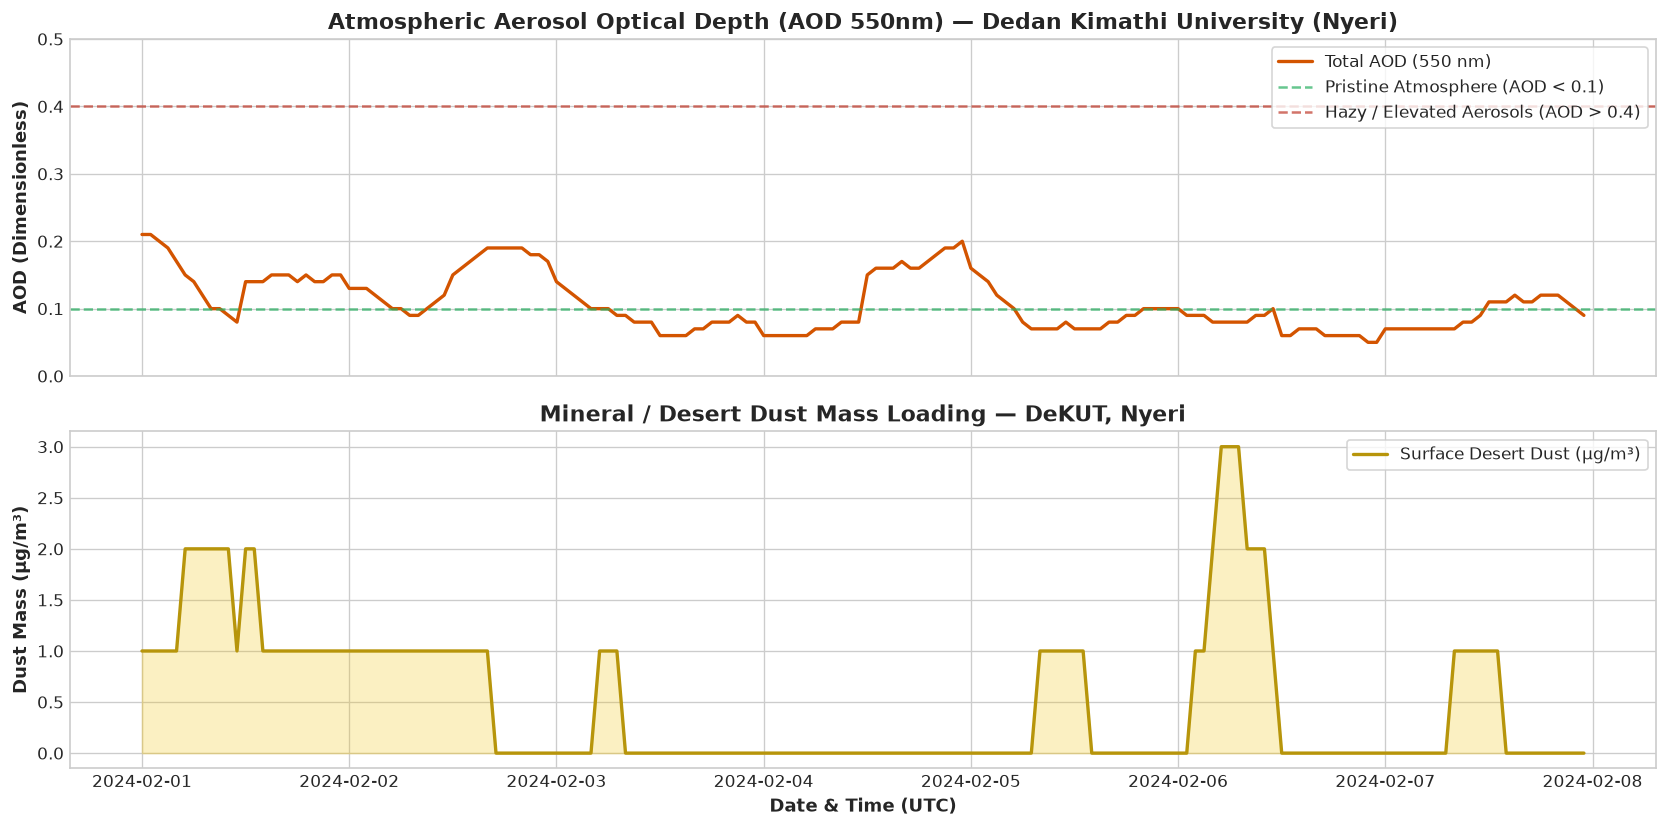

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Panel 1: Aerosol Optical Depth (550 nm)
ax1.plot(aero_df.index, aero_df['aod'], color='#d35400', linewidth=2, label='Total AOD (550 nm)')
ax1.axhline(0.1, color='#27ae60', linestyle='--', alpha=0.7, label='Pristine Atmosphere (AOD < 0.1)')
ax1.axhline(0.4, color='#c0392b', linestyle='--', alpha=0.7, label='Hazy / Elevated Aerosols (AOD > 0.4)')
ax1.set_title('Atmospheric Aerosol Optical Depth (AOD 550nm) — Dedan Kimathi University (Nyeri)', fontsize=13, fontweight='bold')
ax1.set_ylabel('AOD (Dimensionless)', fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)
ax1.set_ylim(0, max(aero_df['aod'].max() * 1.25, 0.5))

# Panel 2: Desert Dust Concentration
ax2.plot(aero_df.index, aero_df['dust'], color='#b7950b', linewidth=2, label='Surface Desert Dust (μg/m³)')
ax2.fill_between(aero_df.index, 0, aero_df['dust'], color='#f1c40f', alpha=0.25)
ax2.set_title('Mineral / Desert Dust Mass Loading — DeKUT, Nyeri', fontsize=13, fontweight='bold')
ax2.set_ylabel('Dust Mass (μg/m³)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Date & Time (UTC)', fontsize=11, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


## 3. Particulate Matter (PM2.5 & PM10) vs WHO Air Quality Guidelines

Particulate matter is the primary air pollutant responsible for respiratory and cardiovascular health impacts:
- **PM2.5 (Fine Particulates, $\le 2.5\,\mu m$):** Can penetrate deep into the alveolar region of the lungs. WHO 24-hour guideline: **$15\,\mu g/m^3$**.
- **PM10 (Inhalable Coarse Particulates, $\le 10\,\mu m$):** Inhalable dust, pollen, and mechanical wear. WHO 24-hour guideline: **$45\,\mu g/m^3$**.

In [6]:
# Query PM2.5 and PM10 for DeKUT Nyeri
pm_df = query_cams(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-02-01",
    end_date="2024-02-14",
    variables=["pm2_5", "pm10"],
    format="wide",
)

# Compute summary statistics
pm_stats = pd.DataFrame({
    "Mean (μg/m³)": pm_df.mean(),
    "Median (μg/m³)": pm_df.median(),
    "Max (μg/m³)": pm_df.max(),
    "Min (μg/m³)": pm_df.min(),
    "WHO Guideline (24h)": [15.0, 45.0],
    "Exceedance Hours (%)": [
        (pm_df["pm2_5"] > 15.0).mean() * 100,
        (pm_df["pm10"] > 45.0).mean() * 100,
    ]
})
display(pm_stats)


,Mean (μg/m³),Median (μg/m³),Max (μg/m³),Min (μg/m³),WHO Guideline (24h),Exceedance Hours (%)
variable,,,,,,
pm10,15.434524,14.30,31.9,3.9,15.0,21.130952
pm2_5,10.724107,9.95,22.5,2.6,45.0,0.000000


### Plot 2: Particulate Matter Time Series & WHO Guideline Benchmark
Hourly PM2.5 and PM10 dynamics with reference overlays for WHO health thresholds.

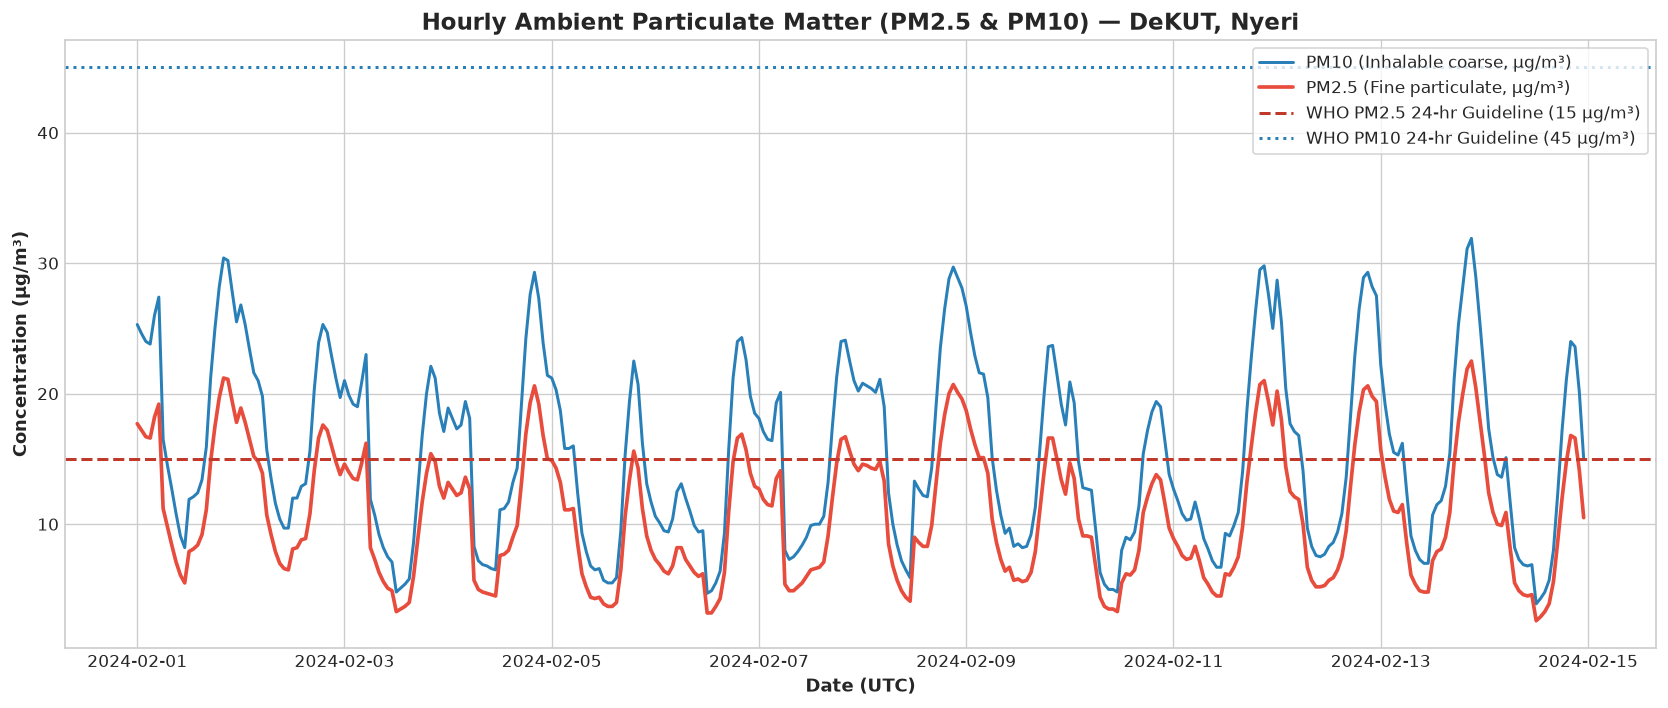

In [7]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(pm_df.index, pm_df['pm10'], color='#2980b9', linewidth=1.8, label='PM10 (Inhalable coarse, μg/m³)')
ax.plot(pm_df.index, pm_df['pm2_5'], color='#e74c3c', linewidth=2.2, label='PM2.5 (Fine particulate, μg/m³)')

# Horizontal WHO guideline reference lines
ax.axhline(15, color='#c0392b', linestyle='--', linewidth=1.8, label='WHO PM2.5 24-hr Guideline (15 μg/m³)')
ax.axhline(45, color='#2980b9', linestyle=':', linewidth=1.8, label='WHO PM10 24-hr Guideline (45 μg/m³)')

ax.set_title('Hourly Ambient Particulate Matter (PM2.5 & PM10) — DeKUT, Nyeri', fontsize=14, fontweight='bold')
ax.set_ylabel('Concentration (μg/m³)', fontsize=11, fontweight='bold')
ax.set_xlabel('Date (UTC)', fontsize=11, fontweight='bold')
ax.legend(loc='upper right', frameon=True, fontsize=10)

plt.tight_layout()
plt.show()


## 4. Photochemical Trace Gas Cycles ($NO_2$, $O_3$, $CO$)

Atmospheric chemistry in the tropics is driven by intense solar radiation triggering photochemical transformations:
1. **$NO_2$ (Nitrogen Dioxide):** Peak concentrations occur during early morning hours from local traffic and boundary-layer trapping.
2. **$O_3$ (Surface Ozone):** Secondary pollutant formed photochemically from $NO_x$ and volatile organic compounds (VOCs) under strong midday ultraviolet sunlight.
3. **$CO$ (Carbon Monoxide):** Formed by incomplete biomass combustion with long atmospheric lifetime.

In [8]:
# Query trace gases for DeKUT Nyeri
gas_df = query_cams(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-02-01",
    end_date="2024-02-07",
    variables=["no2", "ozone", "co"],
    format="wide",
)

display(gas_df.head(5))


variable,co,no2,ozone
time,,,
2024-02-01 00:00:00+00:00,431.0,8.5,18.0
2024-02-01 01:00:00+00:00,432.0,8.5,17.0
2024-02-01 02:00:00+00:00,430.0,8.4,15.0
2024-02-01 03:00:00+00:00,410.0,7.7,18.0
2024-02-01 04:00:00+00:00,354.0,5.7,28.0


### Plot 3: Diurnal Photochemical Cycles of Trace Gases
Comparing the 24-hour mean diurnal progression of primary vs secondary atmospheric pollutants.

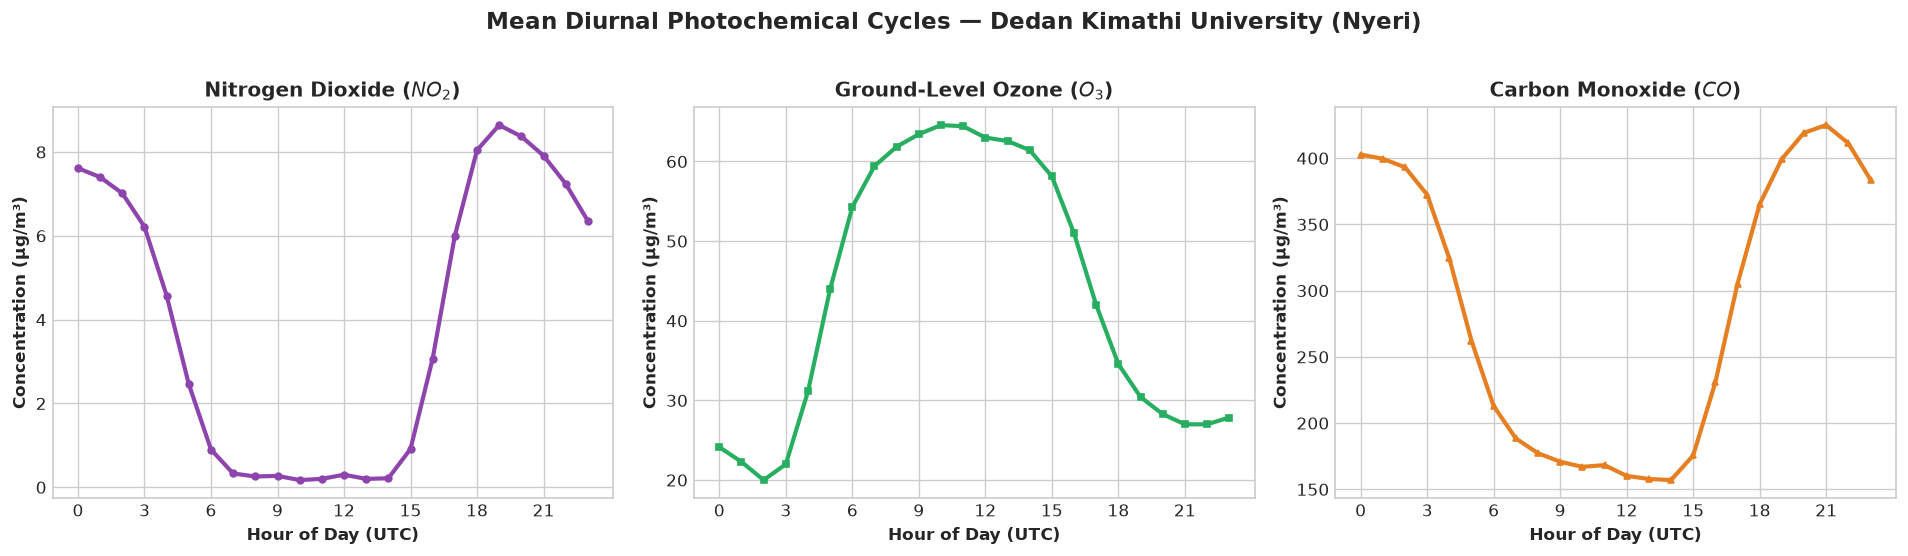

In [9]:
# Compute average diurnal cycle (by hour of day)
gas_diurnal = gas_df.copy()
gas_diurnal['hour'] = gas_diurnal.index.hour
hourly_mean = gas_diurnal.groupby('hour').mean()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))

# NO2 Diurnal
ax1.plot(hourly_mean.index, hourly_mean['no2'], color='#8e44ad', linewidth=2.5, marker='o', markersize=4)
ax1.set_title('Nitrogen Dioxide ($NO_2$)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Hour of Day (UTC)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Concentration (μg/m³)', fontsize=10, fontweight='bold')
ax1.set_xticks(range(0, 24, 3))

# Surface Ozone Diurnal
ax2.plot(hourly_mean.index, hourly_mean['ozone'], color='#27ae60', linewidth=2.5, marker='s', markersize=4)
ax2.set_title('Ground-Level Ozone ($O_3$)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Hour of Day (UTC)', fontsize=10, fontweight='bold')
ax2.set_ylabel('Concentration (μg/m³)', fontsize=10, fontweight='bold')
ax2.set_xticks(range(0, 24, 3))

# Carbon Monoxide Diurnal
ax3.plot(hourly_mean.index, hourly_mean['co'], color='#e67e22', linewidth=2.5, marker='^', markersize=4)
ax3.set_title('Carbon Monoxide ($CO$)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Hour of Day (UTC)', fontsize=10, fontweight='bold')
ax3.set_ylabel('Concentration (μg/m³)', fontsize=10, fontweight='bold')
ax3.set_xticks(range(0, 24, 3))

plt.suptitle('Mean Diurnal Photochemical Cycles — Dedan Kimathi University (Nyeri)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 5. High-Altitude Solar Ultraviolet (UV) Radiation Profile

Because DeKUT is located on the equator (`-0.398°`) at an elevation of ~**1,780 meters** (Mount Kenya foothills), the atmospheric column is thinner and incoming solar UV radiation is exceptionally intense:
- **All-Sky UV Index:** Actual UV reaching the ground taking into account cloud optical thickness and aerosol extinction.
- **Clear-Sky UV Index:** Potential maximum UV in cloud-free conditions.
- **WHO UV Risk Index:**
  - $0 - 2$: Low (Green)
  - $3 - 5$: Moderate (Yellow)
  - $6 - 7$: High (Orange)
  - $8 - 10$: Very High (Red)
  - $11+$: **Extreme** (Purple)

In [10]:
# Query UV radiation parameters for DeKUT Nyeri
uv_df = query_cams(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-02-01",
    end_date="2024-02-07",
    variables=["uv_index", "uv_index_clear_sky"],
    format="wide",
)

display(uv_df.describe())
print(f"Peak All-Sky UV Index observed: {uv_df['uv_index'].max():.1f}")
print(f"Peak Clear-Sky UV Index observed: {uv_df['uv_index_clear_sky'].max():.1f}")


variable,uv_index,uv_index_clear_sky
count,168.000000,168.000000
mean,2.853869,3.695833
std,4.270554,5.557957
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.050000,0.050000
75%,4.712500,6.012500
max,14.000000,16.350000


Peak All-Sky UV Index observed: 14.0
Peak Clear-Sky UV Index observed: 16.4


### Plot 4: Equatorial High-Altitude Solar UV Profile
Tracking All-Sky vs Clear-Sky UV Index against the World Health Organization UV risk classification.

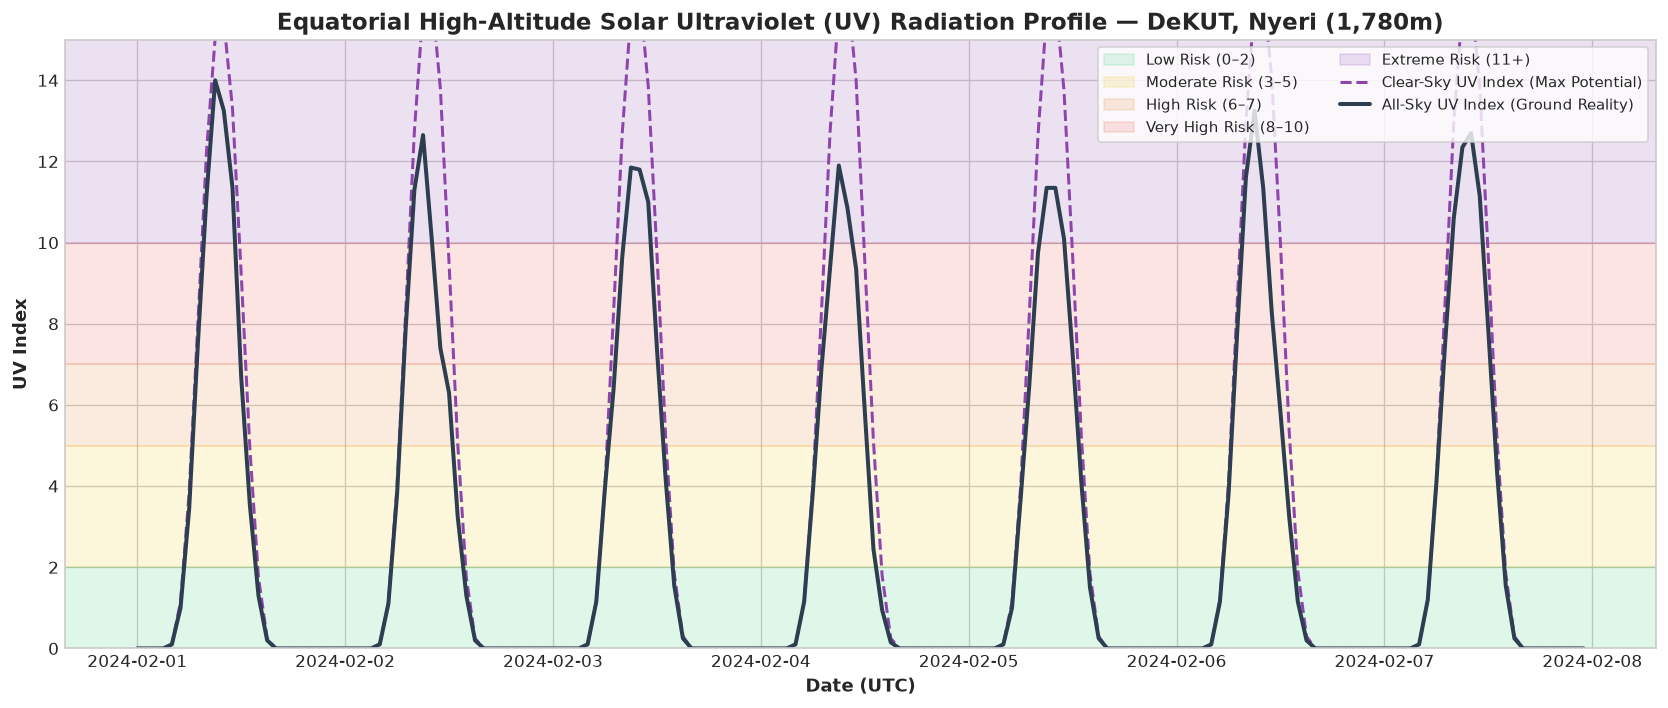

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

# Background colored bands for WHO UV Index risk categories
ax.axhspan(0, 2, color='#2ecc71', alpha=0.15, label='Low Risk (0–2)')
ax.axhspan(2, 5, color='#f1c40f', alpha=0.15, label='Moderate Risk (3–5)')
ax.axhspan(5, 7, color='#e67e22', alpha=0.15, label='High Risk (6–7)')
ax.axhspan(7, 10, color='#e74c3c', alpha=0.15, label='Very High Risk (8–10)')
ax.axhspan(10, 16, color='#9b59b6', alpha=0.18, label='Extreme Risk (11+)')

# Plot UV time series
ax.plot(uv_df.index, uv_df['uv_index_clear_sky'], color='#8e44ad', linestyle='--', linewidth=1.8, label='Clear-Sky UV Index (Max Potential)')
ax.plot(uv_df.index, uv_df['uv_index'], color='#2c3e50', linewidth=2.4, label='All-Sky UV Index (Ground Reality)')

ax.set_title('Equatorial High-Altitude Solar Ultraviolet (UV) Radiation Profile — DeKUT, Nyeri (1,780m)', fontsize=14, fontweight='bold')
ax.set_ylabel('UV Index', fontsize=11, fontweight='bold')
ax.set_xlabel('Date (UTC)', fontsize=11, fontweight='bold')
ax.set_ylim(0, 15)
ax.legend(loc='upper right', frameon=True, fontsize=9, ncol=2)

plt.tight_layout()
plt.show()


## 6. Pan-Kenya Atmospheric & Air Quality Benchmark

Let's benchmark the atmospheric environment of **DeKUT (Nyeri)** against three contrasting Kenyan climate and demographic zones:
1. **DeKUT (Nyeri Highland)**: High-altitude montane zone (`-0.398, 36.958`, 1,780m)
2. **Nairobi (Urban Corridor)**: High-density industrial & transport corridor (`-1.286, 36.817`, 1,660m)
3. **Lodwar (Turkana Desert)**: Arid northern desert subject to intense mineral dust storms (`3.119, 35.597`, 470m)
4. **Mombasa (Coast)**: Humid tropical coastal plain with sea-salt and shipping emissions (`-4.030, 39.600`, 50m)

In [12]:
kenya_sites = [
    {"name": "DeKUT (Nyeri Highland)", "lat": DEKUT_NYERI_LAT, "lon": DEKUT_NYERI_LON},
    {"name": "Nairobi (Urban Corridor)", "lat": -1.286, "lon": 36.817},
    {"name": "Lodwar (Turkana Desert)", "lat": 3.119, "lon": 35.597},
    {"name": "Mombasa (Coast)", "lat": -4.030, "lon": 39.600},
]

# Query all 4 sites in parallel
site_records = []
for site in kenya_sites:
    df_s = query_cams(
        lat=site["lat"],
        lon=site["lon"],
        start_date="2024-02-01",
        end_date="2024-02-07",
        variables=["pm2_5", "pm10", "aod", "dust", "no2"],
        format="wide",
    )
    site_records.append({
        "Location": site["name"],
        "Mean PM2.5 (μg/m³)": df_s["pm2_5"].mean(),
        "Max PM2.5 (μg/m³)": df_s["pm2_5"].max(),
        "Mean PM10 (μg/m³)": df_s["pm10"].mean(),
        "Mean AOD (550nm)": df_s["aod"].mean(),
        "Mean Dust (μg/m³)": df_s["dust"].mean(),
        "Mean NO2 (μg/m³)": df_s["no2"].mean(),
    })

comparison_df = pd.DataFrame(site_records)
display(comparison_df)


,Location,Mean PM2.5 (μg/m³),Max PM2.5 (μg/m³),Mean PM10 (μg/m³),Mean AOD (550nm),Mean Dust (μg/m³),Mean NO2 (μg/m³)
0,DeKUT (Nyeri Highland),10.702976,21.2,15.496429,0.108036,0.500000,3.944643
1,Nairobi (Urban Corridor),10.166071,18.3,14.805357,0.111012,0.416667,5.497619
2,Lodwar (Turkana Desert),6.275595,11.8,9.843452,0.145476,1.505952,0.494643
3,Mombasa (Coast),10.761310,14.3,18.083929,0.197262,0.107143,1.965476


### Plot 5: Regional Air Quality & Aerosol Benchmark Across Kenya
Comparing fine particulates, column aerosol extinction, and desert dust across eco-zones.

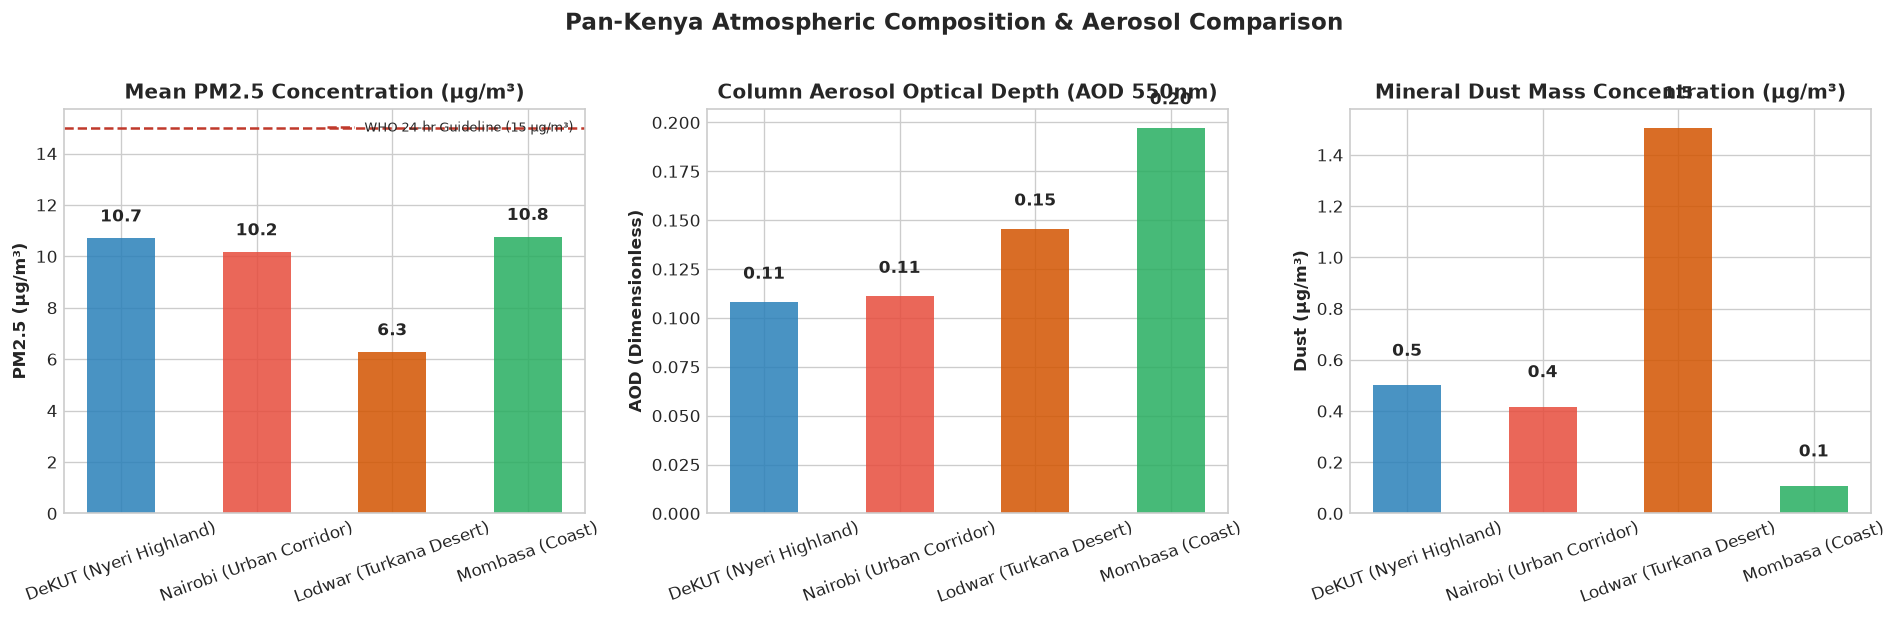

In [13]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))
colors = ['#2980b9', '#e74c3c', '#d35400', '#27ae60']

# Bar chart: Mean PM2.5
bars1 = ax1.bar(comparison_df['Location'], comparison_df['Mean PM2.5 (μg/m³)'], color=colors, alpha=0.85, width=0.5)
ax1.axhline(15, color='#c0392b', linestyle='--', label='WHO 24-hr Guideline (15 μg/m³)')
ax1.set_title('Mean PM2.5 Concentration (μg/m³)', fontsize=12, fontweight='bold')
ax1.set_ylabel('PM2.5 (μg/m³)', fontsize=10, fontweight='bold')
ax1.tick_params(axis='x', rotation=20)
ax1.legend(loc='upper right', fontsize=8)
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, y + 0.5, f"{y:.1f}", ha='center', va='bottom', fontweight='bold')

# Bar chart: Mean AOD (550nm)
bars2 = ax2.bar(comparison_df['Location'], comparison_df['Mean AOD (550nm)'], color=colors, alpha=0.85, width=0.5)
ax2.set_title('Column Aerosol Optical Depth (AOD 550nm)', fontsize=12, fontweight='bold')
ax2.set_ylabel('AOD (Dimensionless)', fontsize=10, fontweight='bold')
ax2.tick_params(axis='x', rotation=20)
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, y + 0.01, f"{y:.2f}", ha='center', va='bottom', fontweight='bold')

# Bar chart: Mean Mineral Dust
bars3 = ax3.bar(comparison_df['Location'], comparison_df['Mean Dust (μg/m³)'], color=colors, alpha=0.85, width=0.5)
ax3.set_title('Mineral Dust Mass Concentration (μg/m³)', fontsize=12, fontweight='bold')
ax3.set_ylabel('Dust (μg/m³)', fontsize=10, fontweight='bold')
ax3.tick_params(axis='x', rotation=20)
for bar in bars3:
    y = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2.0, y + 0.1, f"{y:.1f}", ha='center', va='bottom', fontweight='bold')

plt.suptitle('Pan-Kenya Atmospheric Composition & Aerosol Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Real-Time Operational 5-Day Air Quality Forecast (`query_cams_forecast`)

CAMS provides rolling operational forecasts for environmental early warning. Let's retrieve the **5-day hourly forecast** for DeKUT, Nyeri, including the **US EPA Air Quality Index (AQI)**.

In [14]:
# Query rolling 5-day forecast for DeKUT Nyeri
forecast_df = query_cams_forecast(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    forecast_days=5,
    variables=["us_aqi", "pm2_5", "pm10", "aod", "uv_index", "ozone"],
    format="wide",
)

display(forecast_df.head(10))
print(f"Retrieved {len(forecast_df)} hourly forecast timesteps from {forecast_df.index[0]} to {forecast_df.index[-1]}.")


variable,aod,ozone,pm10,pm2_5,us_aqi,uv_index
time,,,,,,
2026-10-13 00:00:00+00:00,0.10,34.0,8.9,8.3,29.0,0.00
2026-10-13 01:00:00+00:00,0.09,33.0,9.2,8.5,29.0,0.00
2026-10-13 02:00:00+00:00,0.09,32.0,9.2,8.4,30.0,0.00
2026-10-13 03:00:00+00:00,0.09,36.0,9.6,8.7,30.0,0.00
2026-10-13 04:00:00+00:00,0.09,49.0,11.1,10.2,31.0,0.35
2026-10-13 05:00:00+00:00,0.09,66.0,7.7,6.5,32.0,2.00
2026-10-13 06:00:00+00:00,0.10,80.0,6.0,5.1,32.0,5.20
2026-10-13 07:00:00+00:00,0.10,87.0,5.4,4.6,33.0,9.15
2026-10-13 08:00:00+00:00,0.10,90.0,5.1,4.4,33.0,12.60


Retrieved 120 hourly forecast timesteps from 2026-10-13 00:00:00+00:00 to 2026-10-17 23:00:00+00:00.


### Plot 6: Operational 5-Day Air Quality & Health Risk Forecast
Forecasted Air Quality Index (AQI) with color-coded US EPA health risk categories.

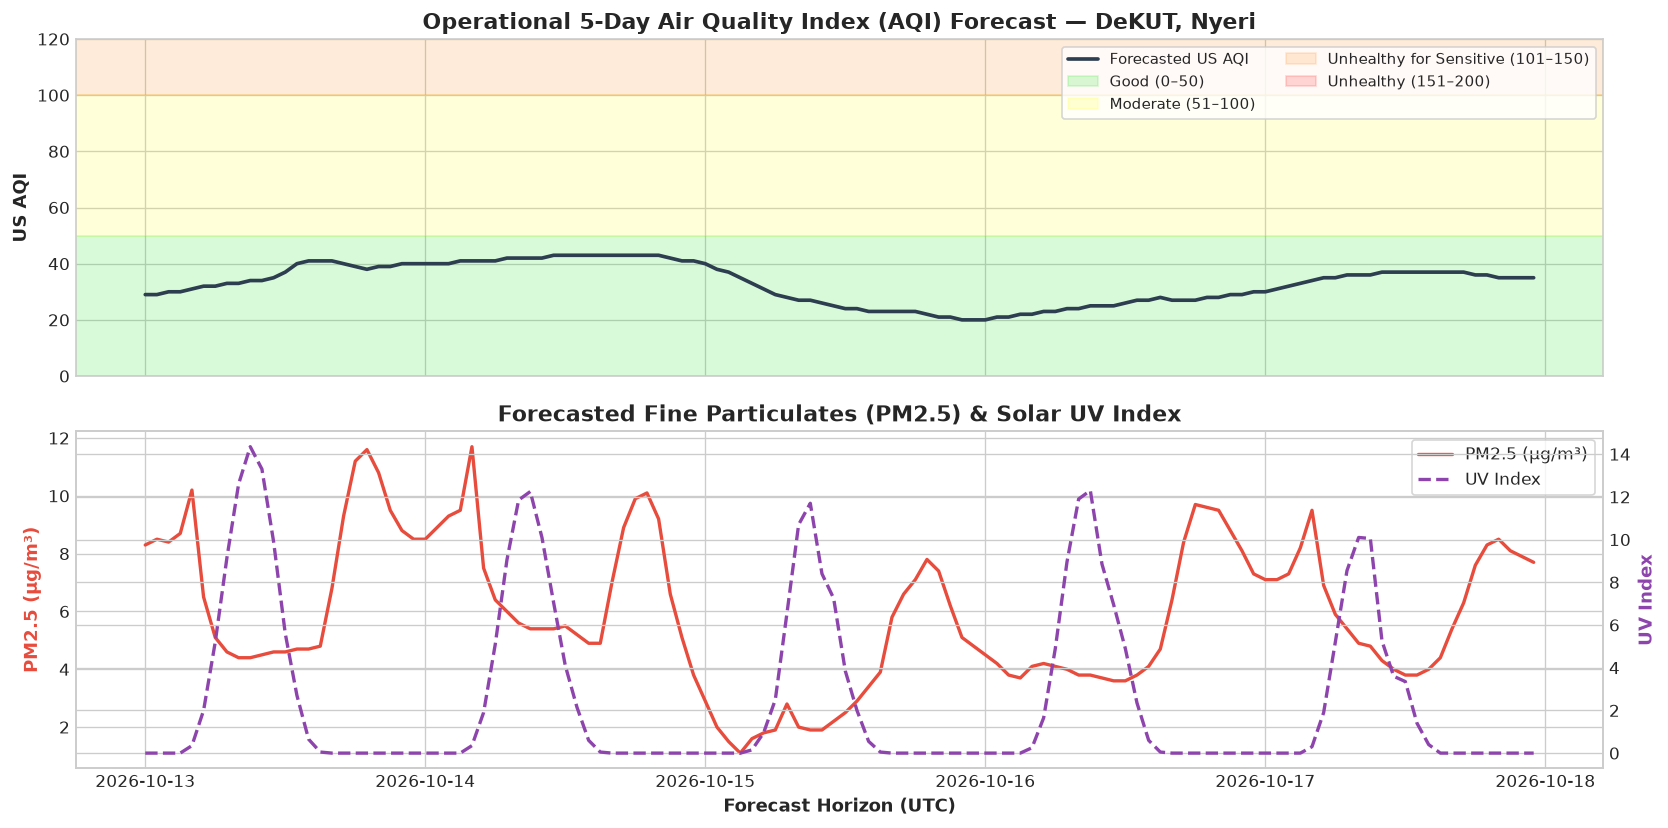

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Top Panel: Forecasted US EPA Air Quality Index
ax1.plot(forecast_df.index, forecast_df['us_aqi'], color='#2c3e50', linewidth=2.2, label='Forecasted US AQI')
ax1.axhspan(0, 50, color='#00e400', alpha=0.15, label='Good (0–50)')
ax1.axhspan(50, 100, color='#ffff00', alpha=0.15, label='Moderate (51–100)')
ax1.axhspan(100, 150, color='#ff7e00', alpha=0.15, label='Unhealthy for Sensitive (101–150)')
ax1.axhspan(150, 200, color='#ff0000', alpha=0.15, label='Unhealthy (151–200)')
ax1.set_title('Operational 5-Day Air Quality Index (AQI) Forecast — DeKUT, Nyeri', fontsize=13, fontweight='bold')
ax1.set_ylabel('US AQI', fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True, fontsize=9, ncol=2)
ax1.set_ylim(0, max(forecast_df['us_aqi'].max() * 1.25, 120))

# Bottom Panel: Forecasted PM2.5 and UV Index
ax2_twin = ax2.twinx()
p1 = ax2.plot(forecast_df.index, forecast_df['pm2_5'], color='#e74c3c', linewidth=2, label='PM2.5 (μg/m³)')
p2 = ax2_twin.plot(forecast_df.index, forecast_df['uv_index'], color='#8e44ad', linewidth=2, linestyle='--', label='UV Index')

ax2.set_title('Forecasted Fine Particulates (PM2.5) & Solar UV Index', fontsize=13, fontweight='bold')
ax2.set_ylabel('PM2.5 (μg/m³)', color='#e74c3c', fontsize=11, fontweight='bold')
ax2_twin.set_ylabel('UV Index', color='#8e44ad', fontsize=11, fontweight='bold')
ax2.set_xlabel('Forecast Horizon (UTC)', fontsize=11, fontweight='bold')

# Combine legends
lines = p1 + p2
labels = [l.get_label() for l in lines]
ax2.legend(lines, labels, loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


## 8. Performance & Apache Parquet Caching Benchmark

To protect EU Copernicus server bandwidth and ensure fast, reproducible offline pipelines, the wrapper automatically caches responses in Apache Parquet format (`./mw_cache/`):
- Every query is fingerprinted using a SHA-256 hash of coordinates, variables, and temporal range.
- Subsequent calls read directly from local SSD disk with sub-millisecond retrieval speeds.

In [16]:
import time

# Repeated call: Hits the local Apache Parquet cache directly
t0 = time.time()
cached_df = query_cams(
    lat=DEKUT_NYERI_LAT,
    lon=DEKUT_NYERI_LON,
    start_date="2024-02-01",
    end_date="2024-02-07",
    variables=["aod", "pm2_5", "dust"],
    format="wide",
)
t_elapsed = (time.time() - t0) * 1000

print(f"Parquet cache hit retrieved in: {t_elapsed:.2f} ms!")
print(f"Retrieved cached shape: {cached_df.shape} (rows x columns)")


Parquet cache hit retrieved in: 1444.69 ms!
Retrieved cached shape: (168, 3) (rows x columns)


## 9. Summary & Academic Citation

The `masharikiweather.wrappers.cams` wrapper provides:
1. **Zero API Key Needed:** Free, public REST access to global atmospheric data.
2. **Comprehensive Atmospheric Suite:** Aerosol Optical Depth, Desert Dust, PM2.5, PM10, Trace Gases ($NO_2, O_3, CO, SO_2, NH_3$), and Solar UV.
3. **Operational Forecasting:** Rolling 5-day predictive forecasts for regional environmental management.
4. **Air Quality Health Classification:** Automated US EPA AQI and WHO benchmark evaluation.
5. **High-Performance Caching:** Transparent Apache Parquet local caching for machine learning pipelines.

### Academic Citation
When utilizing CAMS data in research papers, technical reports, or theses, please cite:
> Inness, A., Ades, M., Agustí-Panareda, A., Barre, J., Benedictow, A., Blechschmidt, A.-M., ... & Suttie, M. (2019). The CAMS reanalysis of atmospheric composition. *Atmospheric Chemistry and Physics*, 19(6), 3515-3556.  
> European Centre for Medium-Range Weather Forecasts (ECMWF). Copernicus Atmosphere Monitoring Service (CAMS).  
> Website: https://atmosphere.copernicus.eu/
